# Three-band intrinsic galaxy structure from real seeing-blurred images


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `galaxy_sersic_structure` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：images (1, 3, 120, 120) float32：Measuredg,r,zflux,nanomaggies/pixel;row/column imageaxes；inverse_variance (1, 3, 120, 120) float32：Supplied inverse noise variance,(nanomaggies/pixel)⁻²；psfs (1, 3, 63, 63) float32：Calibratedg,r,zpoint-spreadkernels,dimensionlessfractionalfluxperkernelpixel；mask (1, 1, 120, 120) bool：Observedneighbor-exclusionmask,Trueexcluded,dimensionless;sharedacrossbands。恢复目标：三band内禀galaxy亮度及每band八个结构/sky参数。

获取模型：pixel-integrated Sersic形态经独立PSF卷积，加sky和观测噪声。实际恢复算法：solvers.fit_band/reconstruct：有界变换参数的Adam MAP优化。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:3不存在实际内禀galaxy真值；baseline为独立标准方法。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：galaxy_sersic_structure.ipynb单元5：5. Results；Actual PSF sensitivity refits；galaxy_sersic_structure.ipynb单元7有保存图；im=ax[0,i].imshow(image,origin='lower',extent=extent,cmap='magma',vmin=0,vmax=limit);fig.colorbar(im,ax=ax[0,i],label='Intrinsic flux(nanomaggies/pixel)');ax[0,i].set_title(band+' ；galaxy_sersic_structure.ipynb单元8有保存图；radial_profiles.append(np.array(profiles));ax[0,i].plot(centers*.262,profiles[0],'.',label='Measured annular mean',color='.4');ax[0,i].plot(centers*.262,profiles[1],label='Fresh co；galaxy_sersic_structure.ipynb单元9有保存图；delta=r['intrinsic'][1]-fresh['reconstruction'][0,1];vmax=np.max(abs(delta));im=a.imshow(delta,origin='lower',extent=extent,cmap='RdBu_r',vmin=-vmax,vmax=vmax);fig.colorbar(im,ax=a。图/比较代码位于单元7, 8, 9（从0计数）。代码单元5个，带execution_count的5个，保存PNG输出5幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->



## 1. Problem

Infer each band's intrinsic extended galaxy brightness and eight structural/sky parameters from real seeing-blurred g/r/z images. Shape, concentration, total flux and background trade off under blur; a smooth Sersic model need not explain every observed feature.

This notebook actively fits all threeg/r/zobservations using local explicit Sérsic pixelquadrature, PSFconvolution, Gaussianlikelihood, transformedphysicalparameters and the selectedthree-roundAdamMAPschedule. IndependentoriginalPySersicrunis a standard-methodcomparison,not truegalaxystructure. Images: **Legacy Surveys / D. Lang (Perimeter Institute)**,CC BY4.0.

The unknowns perband arecentroidxc,yc,totalinfinite-profilefluxF,major-axishalf-lightradiusre,Sérsicindexn,ellipticitye,angleθandconstantresidualsky. Intrinsic radialprofileI∝exp[−bn(R/re)^(1/n)] has an analytically normalizedtotalflux. Integrate central12×12pixels with12×12Gauss–Legendrequadrature;sampleotherpixelcenters,thenconvolvebytheknownPSF. Positivepixelyisnorth;positivepixelxwest. Modelorientationaddsπ/2toθ. Every output quantity and all threebands are retained.


## 2. Data

The fixed author-selected 120 by 120 DECaLS region retains 0.262 arcsec sampling, real flux images, inverse variances, calibrated 63 by 63 PSFs and a public neighbor mask. Flux units are nanomaggies per pixel. Original-method reconstructions provide comparison, not true galaxy morphology.

These are real measured three-band coadds, pixelized observational PSFs and inverse-variance maps. The120×120source-centered region is the original author example's fixedscientificROI(68:188fromthe256×256cutout), preserving native0.262arcsec pixels. The public mask identifies other observed sources from the r-band segmentation,not the inferred target profile. MaskTrueexcludes thosepixels from fitting in allbands; their original values remain available. No target-derived calibration is supplied.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| images | (1,3,120,120) | float32 | Measuredg,r,zflux,nanomaggies/pixel;row/column imageaxes |
| inverse_variance | (1,3,120,120) | float32 | Supplied inverse noise variance,(nanomaggies/pixel)⁻² |
| psfs | (1,3,63,63) | float32 | Calibratedg,r,zpoint-spreadkernels,dimensionlessfractionalfluxperkernelpixel |
| mask | (1,1,120,120) | bool | Observedneighbor-exclusionmask,Trueexcluded,dimensionless;sharedacrossbands |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Survey | DECaLS DR9-south | — | Real opticalcoaddedobservations |
| Target center | RA59.1067,Dec−30.4848 | degree | Original example cutout skyposition |
| Bands | g,r,z | — | Fixed bandaxisorder |
| Pixel size | 0.262 | arcsec/pixel | Nativeangularsampling |
| Field size | 31.44×31.44 | arcsec | Complete selected120×120region |
| Imageaxisorientation | +columnwest,+rownorth | — | NegativeRA/positiveDec FITSCDdiagonal |
| Localorigin | (59.5,59.5) | pixel | Geometriccenter;centroidremainsunknown |
| Flux calibration | ABmagnitude22.5correspondsto1nanomaggy | — | Surveylinearfluxunit;noindependentbandgainfit |
| PSFcenter | (31,31) | kernelpixel | Zero-based63×63kernelcenter |
| Noise model | Independent Gaussianusing inverse_variance | — | Approximation;coaddcorrelationsandmodelresidualremain |
| Background | Independent unknownconstantperband | nanomaggies/pixel | Residualskyisfitted,notprivilegedinput |
| Boundary | Periodicon120×120grid | — | SelectedFFTconvolutionconvention |
| Source mask | r-band3RMSsegmentation,keepcentralobject | — | Publicobserved-neighborcalibration,notanswer-derived |

Credit: **Legacy Surveys / D. Lang (Perimeter Institute)**. Survey images are licensedCC BY4.0; original values were only losslessly packaged into NPZ and the author-scopedROI/mask was retained.


## 3. Physics

The measured image equals the calibrated PSF convolved with pixel-integrated Sersic brightness plus an unknown constant sky and measurement/model error. The full profile normalization, elliptical coordinates and half-light definition are retained below; finite-grid flux must not be renormalized to the infinite-profile total.

Infer an independent elliptical Sérsic light distribution and constant residual sky level in each of theg,r,z images of one DECaLS DR9-south galaxy. The image model is


$$
y_b(i,j)=[P_b*I_b](i,j)+s_b+\epsilon_b(i,j),
\qquad I_b(R)=\frac{F_b\,b_n^{2n}}{2\pi n\Gamma(2n)r_e^2(1-e)}
\exp[-b_n(R/r_e)^{1/n}].
$$


Here b indexes band, y is measured flux per pixel, P is the known calibrated point-spread function, I is intrinsic surface brightness, s is constant sky flux per pixel and ε is measurement/model error. F is total profile flux integrated over the infinite plane, re the major-axis half-light radius inpixels, n the dimensionless Sérsic concentration ande=1−axisratio the ellipticity. Γ is the gammafunction and bn is the positive constant satisfying the half-light relation γ(2n,bn)=Γ(2n)/2, where γ is the lower incomplete gammafunction. For offsets x−xc,y−yc from centroid, rotate by angleθ+π/2 to obtain major/minor coordinates X,Y and let R=sqrt[X²+(Y/(1−e))²]. Pixelx increases with imagecolumn (westward),pixely withrow (northward); θ is measured counterclockwise from positivepixely in this pixel-coordinate definition. Define model centroids in zero-based pixelcoordinates, centers0..119.

Integrate the central pixels when evaluating the sharply varying profile, and model the calibrated PSF rather than interpreting its blurred core as intrinsic concentration. For this task use periodic convolution on the stated image grid; the galaxy is well inside the boundary. PixelizedPSFs are centered at pixel31in each63×63kernel. The selected numerical convention applies the original approximateπconstant3.1415 for the PSF Fourier shift, an independently quantified0.000914pixeloffset peraxis, which is below the declared structural tolerance. No fitted gain or offset alignment is allowed after reconstruction.

### Radial physics and numerical optimization

Compute annular profiles directly from actual unmaskedpixels around eachfreshcentroid; these circularannuli are a diagnostic,not theellipticalfitcoordinate. Compare measuredbrightness with the freshly convolvedmodel and inspect normalizedresidual distributions. The threeoriginalbandfits areindependent, with the same publicPSFs/noise as localfits.

The original renderer uses a3.1415 Fouriercenteringconstant, which implies0.000914pixelshift peraxis for63pixelkernels; it is preserved and independently quantified, not silently called exactπ. Original randomprior-medianinitialization is replaced by a deterministic geometriccenter59.5, avoiding the derivative singularity at exactintegerpixelcoincidence without inserting a physicalcorefloor. The objective, priors, renderer and three-roundAdam/early-stopping family are retained. Float32sumlossplateaus can stop atslightlydifferentparameters despite highimageagreement.


## 4. Method

The local code evaluates central Gauss-Legendre quadrature, periodic PSF convolution, Gaussian likelihood, transformed parameters and the selected three-round Adam MAP schedule. The 3.1415 PSF-shift convention and deterministic noninteger initialization are explicit numerical choices.

Use a PSF-convolved elliptical Sérsic model with accurate centralpixelintegration. A Gaussian likelihood weights each unmaskedpixel by its suppliedvariance; weakposition/backgroundpriors and boundedphysicalprofileparameters stabilize the morphology/backgroundtradeoff. Gradient-based maximuma-posterior fitting can work in unconstrainedvariables with transformedpositive/boundedparameters. Fit allthreebandsandinspectactualresiduals, rather than equating numericalagreement with a true detailedgalaxymap.


## 5. Results

All three band fits, normalized residuals, annular profiles, parameter comparisons and two fresh PSF sensitivity refits remain visible. Circular diagnostic annuli differ from elliptical model coordinates. The standalone evaluator checks every physical parameter and intrinsic map without post-hoc alignment.

### Real observations, independently reproduced model and fresh residual

Eachbandcomparison uses identical physicalbrightnessscale; display limits are99.5thpercentile only for legibility. The signed residual is(observed−model)/suppliedRMS, displayed±5and explicitly clipped for display; evaluation arrays remain unmodified. Grayexcludedregions are the same public r-bandneighborsegmentationmask. Structured galaxyresiduals and correlatedcoaddnoise can remain under a one-profile approximation; this does not become a fabricated detailedtruegalaxy.

### Actual PSF sensitivity refits

Refit allthreebands twice: neglectseeing with adeltaPSF, and broaden the measuredPSF by a0.5pixelGaussiantransferfactor. These are labeled hypotheticalmodel/calibration experiments, not alternate truePSF measurements. Broadening is computed from the publicPSF without targetinformation. Show actualinferredsize/concentration changes and the intrinsicr-bandimage differences. This preserves the selectedmethod's core PSF/structuretradeoff; no missingmethod is filled with a cachedoriginalresult.

The larger sourcepackage also demonstrates jointmultibandposteriorinference. This fixedtask selects independentthree-bandGaussianMAP unknowns and does not claimjointposterioruncertainties or multibandcouplingbenefits; those distinctstatisticalmodels are explicitly outside the selectedoutput contract.

### Independent full-output evaluator

Evaluate the actualfresh all-band intrinsicmaps and everyphysicalparameter. No magnitude,flux,centroid,angle orsky alignment occurs. Independentanalyticnormalization/half-light andfinite-differencegradientchecks supplement originalstage/fullfitparity. Physicalaccuracy remains limited by single-profilemorphology, diagonalnoise andperiodicPSFapproximation; structuredresiduals are not concealed.


In [1]:
from pathlib import Path
import sys,time,json,numpy as np,torch,matplotlib.pyplot as plt
from IPython.display import display
torch.set_num_threads(1)
root=Path.cwd()if(Path.cwd()/'src').is_dir()else Path.cwd().parent;sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct,fit_band,INITIAL_LATENT
from src.physics_model import PixelModel,objective
from src.visualization import metrics,image_comparison
data=load_data(root/'data/raw_data.npz');start=time.perf_counter();fresh,d=reconstruct(data,return_diagnostics=True);runtime=time.perf_counter()-start
with np.load(root/'evaluation/baseline_reference.npz',allow_pickle=False)as a:original={k:a[k]for k in fresh}
with np.load(root/'test/fixtures/upstream_stages.npz',allow_pickle=False)as a:original_observed=a['output_observed'][0]
original_meta=json.loads((root/'notebooks/reference_outputs/upstream_measurements.json').read_text())
observed=d['observed'];plots={};valid=~data['mask'][0]
measurements={'fresh_runtime_seconds':runtime,'original_runtime_seconds':original_meta['runtime_seconds'],'image_agreement':[metrics(fresh['reconstruction'][0,i],original['reconstruction'][0,i])for i in range(3)],'parameter_absolute_difference':abs(fresh['parameters']-original['parameters']).tolist(),'mean_unmasked_chi_squared':[float(np.mean(((data['images'][i]-observed[i])**2*data['inverse_variance'][i])[valid]))for i in range(3)],'masked_fraction':float(data['mask'].mean())}
print(json.dumps(measurements,indent=2))


{
  "fresh_runtime_seconds": 53.05612000008114,
  "original_runtime_seconds": 29.025781099917367,
  "image_agreement": [
    {
      "ncc": 0.999999999732583,
      "nrmse": 1.453683133791556e-06
    },
    {
      "ncc": 0.9999999863472755,
      "nrmse": 8.716335021060914e-06
    },
    {
      "ncc": 0.9999999996752418,
      "nrmse": 1.1959933150254598e-06
    }
  ],
  "parameter_absolute_difference": [
    [
      [
        0.0,
        3.814697265625e-06,
        0.0001697540283203125,
        6.151199340820312e-05,
        5.0127506256103516e-05,
        1.6391277313232422e-06,
        4.76837158203125e-07,
        4.0068698581308126e-08
      ],
      [
        3.814697265625e-06,
        4.1961669921875e-05,
        0.0023136138916015625,
        0.0006012916564941406,
        0.00041431188583374023,
        1.627206802368164e-05,
        7.152557373046875e-07,
        1.6562262317165732e-07
      ],
      [
        3.814697265625e-06,
        3.814697265625e-06,
        0.000

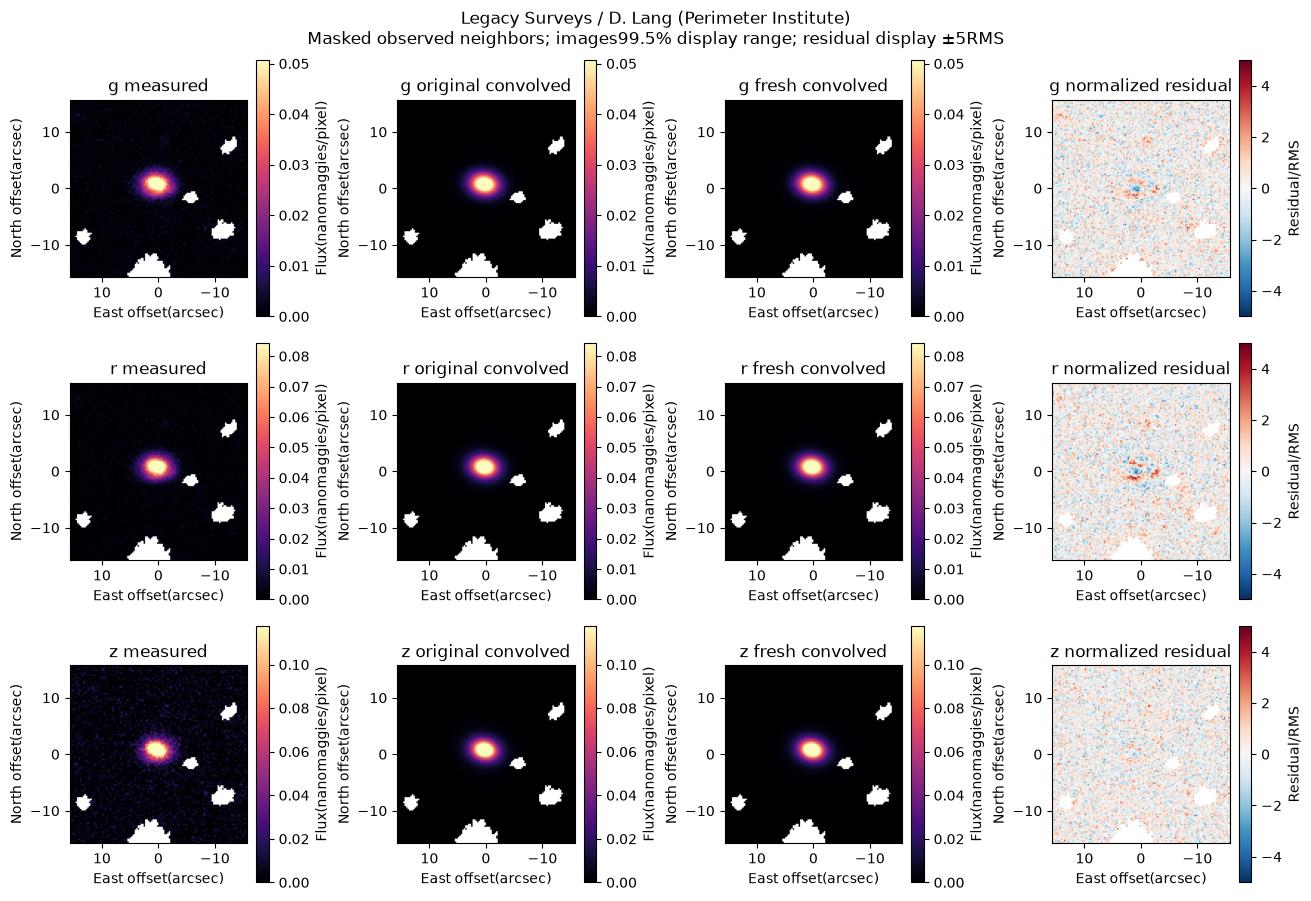

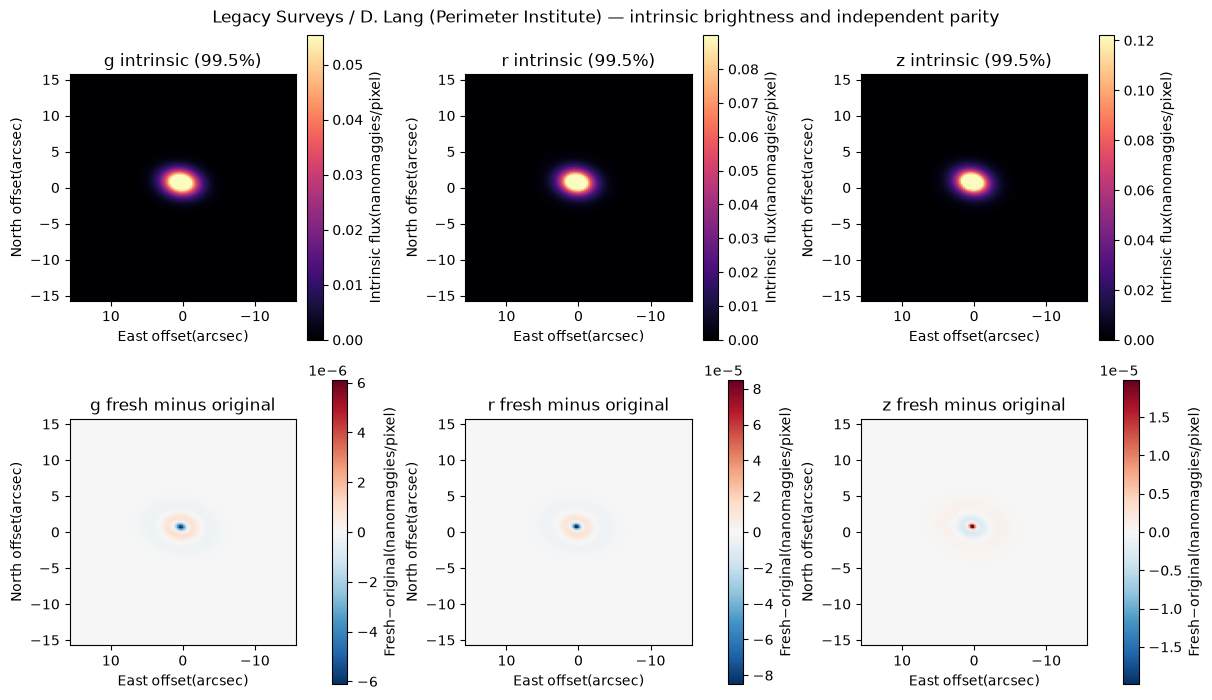

In [2]:
plots['observed_model_residual']=image_comparison(data,observed,original_observed);plt.close('all');display(plots['observed_model_residual'])
fig,ax=plt.subplots(2,3,figsize=(12,7),layout='constrained');extent=[15.72,-15.72,-15.72,15.72]
for i,band in enumerate('grz'):
    image=fresh['reconstruction'][0,i];delta=image-original['reconstruction'][0,i];limit=np.percentile(image,99.5)
    im=ax[0,i].imshow(image,origin='lower',extent=extent,cmap='magma',vmin=0,vmax=limit);fig.colorbar(im,ax=ax[0,i],label='Intrinsic flux(nanomaggies/pixel)');ax[0,i].set_title(band+' intrinsic (99.5%)')
    limit=max(float(np.max(abs(delta))),1e-15);im=ax[1,i].imshow(delta,origin='lower',extent=extent,cmap='RdBu_r',vmin=-limit,vmax=limit);fig.colorbar(im,ax=ax[1,i],label='Fresh−original(nanomaggies/pixel)');ax[1,i].set_title(band+' fresh minus original')
    for a in ax[:,i]:a.set(xlabel='East offset(arcsec)',ylabel='North offset(arcsec)')
fig.suptitle('Legacy Surveys / D. Lang (Perimeter Institute) — intrinsic brightness and independent parity')
plots['intrinsic_profiles']=fig;plt.close(fig);display(fig)


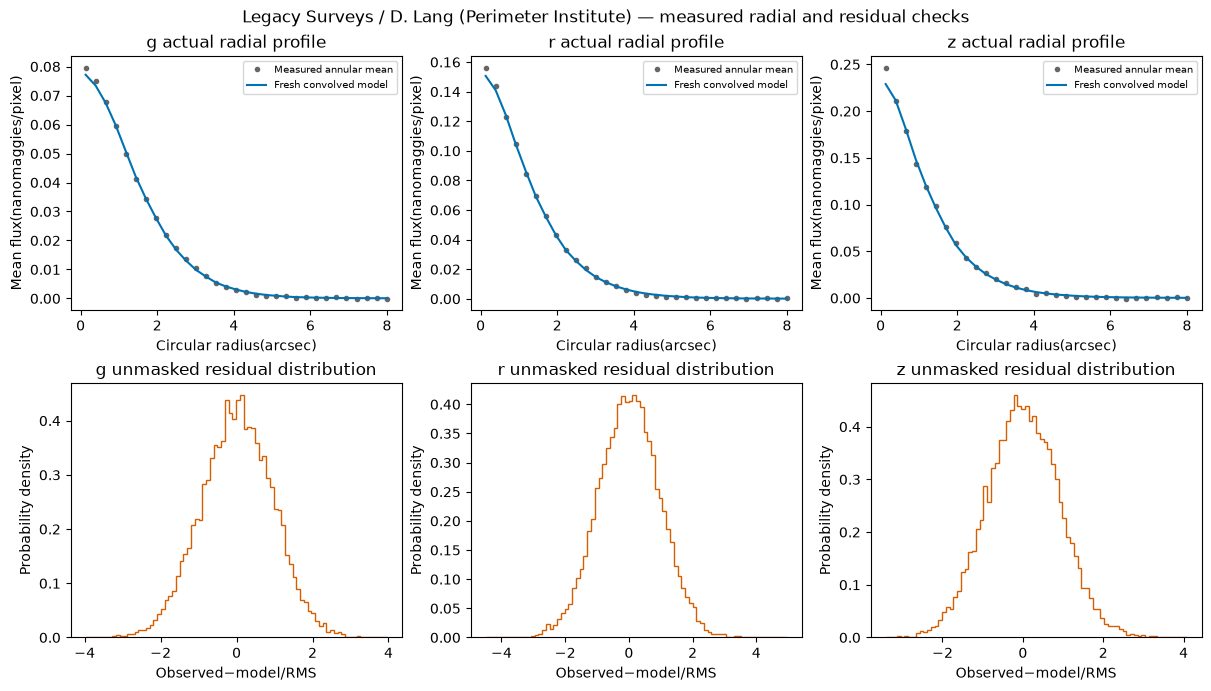

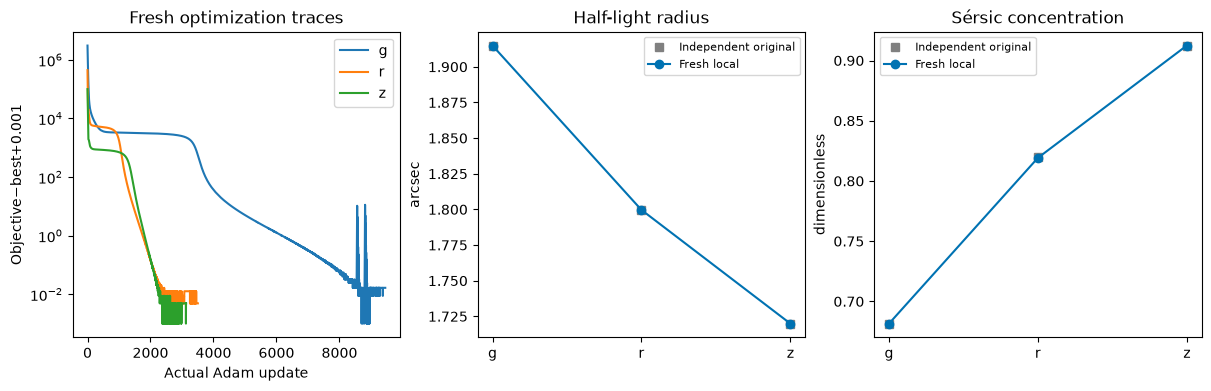

In [3]:
yy,xx=np.indices((120,120));radial_profiles=[]
fig,ax=plt.subplots(2,3,figsize=(12,6.8),layout='constrained')
for i,band in enumerate('grz'):
    p=fresh['parameters'][0,i];radius=np.sqrt((xx-p[0])**2+(yy-p[1])**2);bins=np.arange(0,32,1.);centers=(bins[:-1]+bins[1:])/2
    profiles=[]
    for array in(data['images'][i],observed[i]):profiles.append(np.array([np.mean(array[(radius>=lo)&(radius<hi)&valid])for lo,hi in zip(bins[:-1],bins[1:])]))
    radial_profiles.append(np.array(profiles));ax[0,i].plot(centers*.262,profiles[0],'.',label='Measured annular mean',color='.4');ax[0,i].plot(centers*.262,profiles[1],label='Fresh convolved model',color='#0072B2');ax[0,i].set(xlabel='Circular radius(arcsec)',ylabel='Mean flux(nanomaggies/pixel)',title=band+' actual radial profile');ax[0,i].legend(fontsize=7)
    resid=((data['images'][i]-observed[i])*np.sqrt(data['inverse_variance'][i]))[valid];ax[1,i].hist(resid,bins=80,histtype='step',density=True,color='#D55E00');ax[1,i].set(xlabel='Observed−model/RMS',ylabel='Probability density',title=band+' unmasked residual distribution')
fig.suptitle('Legacy Surveys / D. Lang (Perimeter Institute) — measured radial and residual checks')
plots['physical_radial']=fig;plt.close(fig);display(fig)
fig,ax=plt.subplots(1,3,figsize=(12,3.8),layout='constrained')
for i,band in enumerate('grz'):h=d['history'][i];ax[0].semilogy(np.maximum(h-h.min()+1e-3,1e-3),label=band)
ax[0].set(xlabel='Actual Adam update',ylabel='Objective−best+0.001',title='Fresh optimization traces');ax[0].legend()
for col,label,index,unit in[(1,'Half-light radius',3,'arcsec'),(2,'Sérsic concentration',4,'dimensionless')]:
    scale=.262 if index==3 else 1.;ax[col].plot(np.arange(3),original['parameters'][0,:,index]*scale,'s',label='Independent original',color='.5');ax[col].plot(np.arange(3),fresh['parameters'][0,:,index]*scale,'o-',label='Fresh local',color='#0072B2');ax[col].set_xticks(np.arange(3),list('grz'));ax[col].set(ylabel=unit,title=label);ax[col].legend(fontsize=8)
plots['optimizer_and_spectral_structure']=fig;plt.close(fig);display(fig)


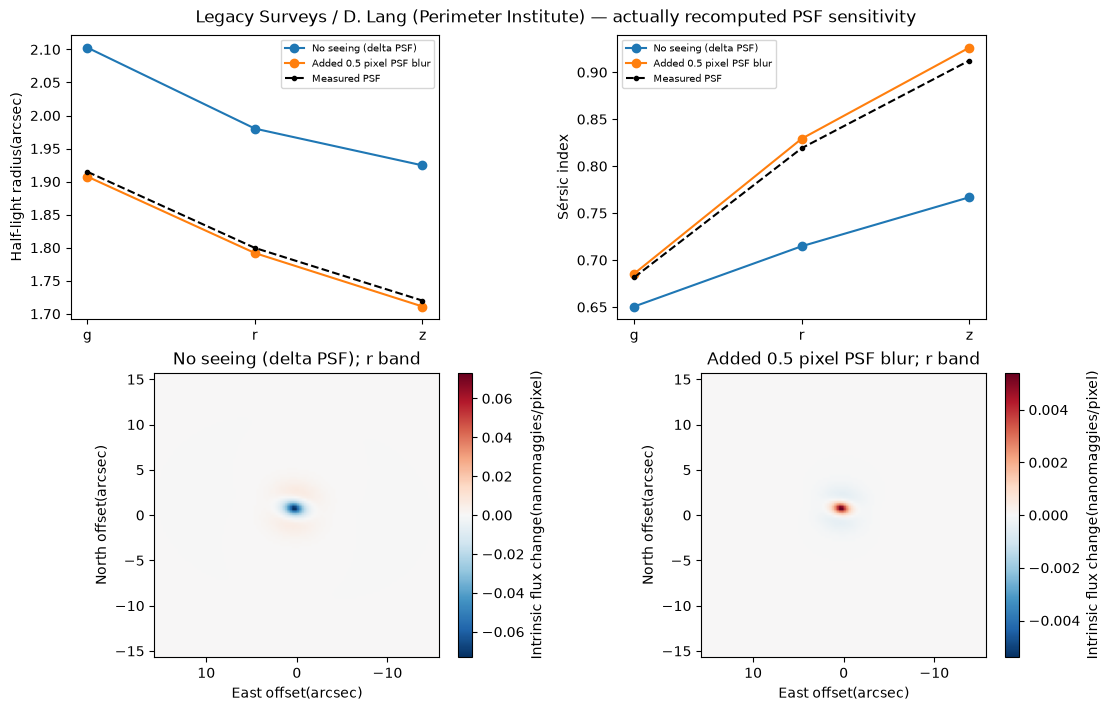

{
  "fresh_runtime_seconds": 53.05612000008114,
  "original_runtime_seconds": 29.025781099917367,
  "image_agreement": [
    {
      "ncc": 0.999999999732583,
      "nrmse": 1.453683133791556e-06
    },
    {
      "ncc": 0.9999999863472755,
      "nrmse": 8.716335021060914e-06
    },
    {
      "ncc": 0.9999999996752418,
      "nrmse": 1.1959933150254598e-06
    }
  ],
  "parameter_absolute_difference": [
    [
      [
        0.0,
        3.814697265625e-06,
        0.0001697540283203125,
        6.151199340820312e-05,
        5.0127506256103516e-05,
        1.6391277313232422e-06,
        4.76837158203125e-07,
        4.0068698581308126e-08
      ],
      [
        3.814697265625e-06,
        4.1961669921875e-05,
        0.0023136138916015625,
        0.0006012916564941406,
        0.00041431188583374023,
        1.627206802368164e-05,
        7.152557373046875e-07,
        1.6562262317165732e-07
      ],
      [
        3.814697265625e-06,
        3.814697265625e-06,
        0.000

In [4]:
variant_results={};variant_psfs={}
for label in('No seeing (delta PSF)','Added 0.5 pixel PSF blur'):
    params=[];intrinsic=[];models=[];psfs=[]
    for i in range(3):
        psf=data['psfs'][i].copy()
        if label.startswith('No'):psf[:]=0;psf[31,31]=1
        else:
            fy,fx=np.meshgrid(np.fft.fftfreq(63),np.fft.rfftfreq(63),indexing='ij');psf=np.fft.irfft2(np.fft.rfft2(psf)*np.exp(-2*np.pi**2*.5**2*(fx**2+fy**2)),s=(63,63)).astype(np.float32)
        p,image,model,h=fit_band(data['images'][i],data['inverse_variance'][i],psf,data['mask'][0],initial_latent=INITIAL_LATENT[i]);params.append(p);intrinsic.append(image);models.append(model);psfs.append(psf)
    variant_results[label]={'parameters':np.array(params),'intrinsic':np.array(intrinsic),'observed':np.array(models)};variant_psfs[label]=np.array(psfs)
measurements['psf_sensitivity_parameters']={label:r['parameters'].tolist()for label,r in variant_results.items()}
fig,ax=plt.subplots(2,2,figsize=(11,7),layout='constrained')
for label,r in variant_results.items():ax[0,0].plot(np.arange(3),r['parameters'][:,3]*.262,'o-',label=label);ax[0,1].plot(np.arange(3),r['parameters'][:,4],'o-',label=label)
for a,index,unit in[(ax[0,0],3,'Half-light radius(arcsec)'),(ax[0,1],4,'Sérsic index')]:a.plot(np.arange(3),fresh['parameters'][0,:,index]*(.262 if index==3 else 1.),'k.--',label='Measured PSF');a.set_xticks(np.arange(3),list('grz'));a.set_ylabel(unit);a.legend(fontsize=7)
for a,(label,r)in zip(ax[1],variant_results.items()):
    delta=r['intrinsic'][1]-fresh['reconstruction'][0,1];vmax=np.max(abs(delta));im=a.imshow(delta,origin='lower',extent=extent,cmap='RdBu_r',vmin=-vmax,vmax=vmax);fig.colorbar(im,ax=a,label='Intrinsic flux change(nanomaggies/pixel)');a.set(title=label+'; r band',xlabel='East offset(arcsec)',ylabel='North offset(arcsec)')
fig.suptitle('Legacy Surveys / D. Lang (Perimeter Institute) — actually recomputed PSF sensitivity')
plots['psf_sensitivity']=fig;plt.close(fig);display(fig);print(json.dumps(measurements,indent=2))


In [5]:
import importlib.util,tempfile
spec=importlib.util.spec_from_file_location('judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
with tempfile.TemporaryDirectory()as directory:
    path=Path(directory)/'fresh.npz';np.savez_compressed(path,**fresh);report,status=judge.evaluate(path)
assert status==0;print(json.dumps(report,indent=2))


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "band_0_ncc": 0.999999999732583,
    "band_0_nrmse": 1.453683133791556e-06,
    "parameter_0_0_absolute_error": 0.0,
    "parameter_0_1_absolute_error": 3.814697265625e-06,
    "parameter_0_2_absolute_error": 0.0001697540283203125,
    "parameter_0_3_absolute_error": 6.151199340820312e-05,
    "parameter_0_4_absolute_error": 5.0127506256103516e-05,
    "parameter_0_5_absolute_error": 1.6391277313232422e-06,
    "parameter_0_6_absolute_error": 4.76837158203125e-07,
    "parameter_0_7_absolute_error": 4.0068698581308126e-08,
    "band_1_ncc": 0.9999999863472755,
    "band_1_nrmse": 8.716335021060914e-06,
    "parameter_1_0_absolute_error": 3.814697265625e-06,
    "parameter_1_1_absolute_error": 4.1961669921875e-05,
    "parameter_1_2_absolute_error": 0.0023136138916015625,
    "parameter_1_3_absolute_error": 0.0006012916564941406,
    "parameter_1_4_absolute_error": 0.00041431188583374023,
    "parameter_1_5_absolute_error": 1.62

## 6. Conclusion

The retained comparisons support selected-method reproduction and expose sensitivity of size/concentration to PSF assumptions. Structured residuals, correlated coadd noise, periodic boundaries and a single-profile approximation limit physical accuracy; joint multiband posterior inference is outside this selected contract.
